# Task 4 - Loan Approval Prediction
**Elevvo ML Internship - Level 2**

Goal: predict whether a loan application will be approved, handling missing values and categorical features, and evaluating on imbalanced data with precision, recall and F1-score.

Dataset: [Loan Approval Prediction (Kaggle)](https://www.kaggle.com/datasets/architsharma01/loan-approval-prediction-dataset) - put `loan_approval_dataset.csv` in the same folder as this notebook (in Colab, upload it with the Files panel). In Colab, also run `!pip install imbalanced-learn rich` once.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

### Terminal-style output

In [2]:
from rich.console import Console
from rich.table import Table
from rich.panel import Panel
from rich import box

console = Console()
GREEN, CYAN, AMBER = '#33ff66', '#00e5ff', '#ffb000'
PALETTE = [GREEN, CYAN, AMBER, '#ff4fd8', '#b388ff', '#ff6e6e', '#ffffff']

plt.style.use('dark_background')
plt.rcParams.update({
    'font.family': 'monospace', 'axes.edgecolor': GREEN, 'axes.labelcolor': GREEN,
    'xtick.color': GREEN, 'ytick.color': GREEN, 'axes.titlecolor': GREEN,
    'axes.grid': True, 'grid.color': '#1f3d1f', 'grid.linestyle': ':',
})

def term_table(df, title, index=True):
    t = Table(title=f'> {title}', title_justify='left', title_style=f'bold {GREEN}',
              box=box.SQUARE, border_style=GREEN, header_style=f'bold {CYAN}')
    if index:
        t.add_column(str(df.index.name or ''), style=AMBER)
    for col in df.columns:
        t.add_column(str(col), justify='right', style=GREEN)
    for idx, *row in df.itertuples():
        values = [f'{v:,.3f}' if isinstance(v, float) else str(v) for v in row]
        t.add_row(*([str(idx)] if index else []), *values)
    console.print(t)

def term_panel(title, lines):
    body = '\n'.join(f'[{GREEN}]$[/] {line}' for line in lines)
    console.print(Panel(body, title=f'[bold {GREEN}]{title}', title_align='left',
                        border_style=GREEN, box=box.SQUARE, expand=False))

## 1. Load and explore the data

In [3]:
df = pd.read_csv('loan_approval_dataset.csv')
# The raw file has spaces around column names and text values
df.columns = df.columns.str.strip()
for col in df.select_dtypes(exclude='number').columns:
    df[col] = df[col].str.strip()
df = df.drop(columns='loan_id')

term_panel('DATASET LOADED', [f'rows    : {df.shape[0]:,}', f'columns : {df.shape[1]}',
                              f'missing : {df.isnull().sum().sum()}', f'duplicates : {df.duplicated().sum()}'])
term_table(df.head(3).T.rename(columns=lambda i: f'applicant {i}'), 'FIRST 3 APPLICANTS')

┌─ DATASET LOADED ──┐
│ $ rows    : 4,269 │
│ $ columns : 12    │
│ $ missing : 0     │
│ $ duplicates : 0  │
└───────────────────┘

> FIRST 3 APPLICANTS                                                   
┌──────────────────────────┬─────────────┬──────────────┬─────────────┐
│                          │ applicant 0 │  applicant 1 │ applicant 2 │
├──────────────────────────┼─────────────┼──────────────┼─────────────┤
│ no_of_dependents         │           2 │            0 │           3 │
│ education                │    Graduate │ Not Graduate │    Graduate │
│ self_employed            │          No │          Yes │          No │
│ income_annum             │     9600000 │      4100000 │     9100000 │
│ loan_amount              │    29900000 │     12200000 │    29700000 │
│ loan_term                │          12 │            8 │          20 │
│ cibil_score              │         778 │          417 │         506 │
│ residential_assets_value │     2400000 │      2700000 │     7100000 │
│ commercial_assets_value  │    17600000 │      2200000 │     4500000 │
│ luxury_assets_value      │    22700000 │      8800000 │    33300000 │
│ bank_asset_value         │     8000000 │      3300000 │    12800000 │
│ loan_status              │    Approved │     Rejected │    Rejected │
└──────────────────────────┴─────────────┴──────────────┴─────────────┘

In [4]:
term_table(df.describe().T.round(0), 'NUMERIC SUMMARY')

> NUMERIC SUMMARY                                                                                                  
┌────────────┬───────────┬────────────┬────────────┬────────────┬────────────┬───────────┬────────────┬───────────┐
│            │     count │       mean │        std │        min │        25% │       50% │        75% │       max │
├────────────┼───────────┼────────────┼────────────┼────────────┼────────────┼───────────┼────────────┼───────────┤
│ no_of_dep… │ 4,269.000 │      2.000 │      2.000 │      0.000 │      1.000 │     3.000 │      4.000 │     5.000 │
│ income_an… │ 4,269.000 │ 5,059,124… │ 2,806,840… │ 200,000.0… │ 2,700,000… │ 5,100,00… │ 7,500,000… │ 9,900,00… │
│ loan_amou… │ 4,269.000 │ 15,133,45… │ 9,043,363… │ 300,000.0… │ 7,700,000… │ 14,500,0… │ 21,500,00… │ 39,500,0… │
│ loan_term  │ 4,269.000 │     11.000 │      6.000 │      2.000 │      6.000 │    10.000 │     16.000 │    20.000 │
│ cibil_sco… │ 4,269.000 │    600.000 │    172.000 │    300.000 │    453.000 │   600.000 │    748.000 │   900.000 │
│ residenti… │ 4,269.000 │ 7,472,617… │ 6,503,637… │ -100,000.… │ 2,200,000… │ 5,600,00… │ 11,300,00… │ 29,100,0… │
│ commercia… │ 4,269.000 │ 4,973,155… │ 4,388,966… │      0.000 │ 1,300,000… │ 3,700,00… │ 7,600,000… │ 19,400,0… │
│ luxury_as… │ 4,269.000 │ 15,126,30… │ 9,103,754… │ 300,000.0… │ 7,500,000… │ 14,600,0… │ 21,700,00… │ 39,200,0… │
│ bank_asse… │ 4,269.000 │ 4,976,692… │ 3,250,185… │      0.000 │ 2,300,000… │ 4,600,00… │ 7,100,000… │ 14,700,0… │
└────────────┴───────────┴────────────┴────────────┴────────────┴────────────┴───────────┴────────────┴───────────┘

## 2. Missing and invalid values
The file has no empty cells, but some asset values are **negative**, which is impossible. We mark them as missing so the pipeline can fill them with the median.

In [5]:
num_cols = df.select_dtypes('number').columns.tolist()
negatives = (df[num_cols] < 0).sum()
term_table(negatives[negatives > 0].to_frame('negative values'), 'INVALID VALUES FOUND')

df[num_cols] = df[num_cols].mask(df[num_cols] < 0)
term_table(df.isnull().sum()[lambda s: s > 0].to_frame('missing (to impute)'), 'MARKED AS MISSING')

> INVALID VALUES FOUND                        
┌──────────────────────────┬─────────────────┐
│                          │ negative values │
├──────────────────────────┼─────────────────┤
│ residential_assets_value │              28 │
└──────────────────────────┴─────────────────┘

> MARKED AS MISSING                               
┌──────────────────────────┬─────────────────────┐
│                          │ missing (to impute) │
├──────────────────────────┼─────────────────────┤
│ residential_assets_value │                  28 │
└──────────────────────────┴─────────────────────┘

## 3. Class balance
Rejected loans are the minority class, so accuracy alone would be misleading. We focus on **precision, recall and F1 for rejected loans**, the ones a bank most needs to catch.

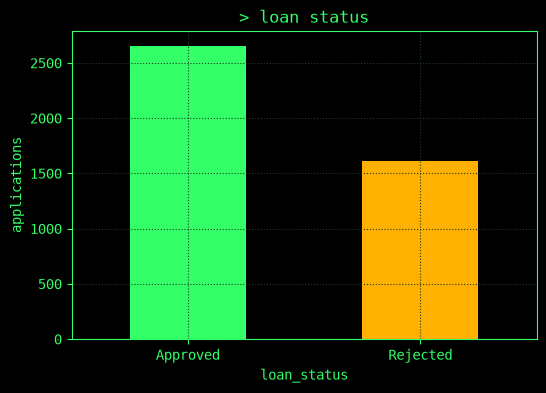

> CLASS BALANCE                       
┌─────────────┬──────────────┬───────┐
│ loan_status │ applications │ share │
├─────────────┼──────────────┼───────┤
│ Approved    │         2656 │ 0.622 │
│ Rejected    │         1613 │ 0.378 │
└─────────────┴──────────────┴───────┘

In [6]:
counts = df['loan_status'].value_counts()
counts.plot(kind='bar', figsize=(6, 4), color=[GREEN, AMBER], title='> loan status')
plt.xticks(rotation=0)
plt.ylabel('applications')
plt.show()
term_table(pd.DataFrame({'applications': counts, 'share': counts / counts.sum()}), 'CLASS BALANCE')

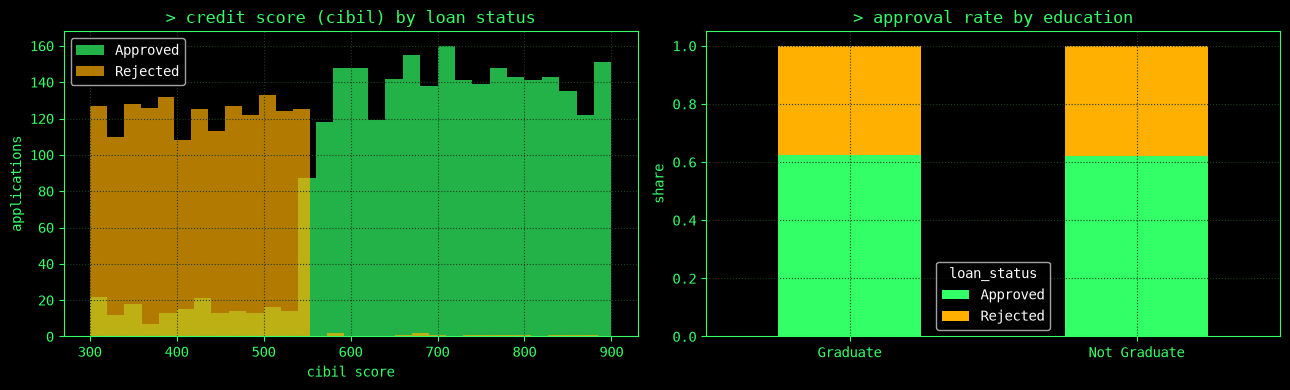

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for status, color in [('Approved', GREEN), ('Rejected', AMBER)]:
    axes[0].hist(df.loc[df.loan_status == status, 'cibil_score'], bins=30, alpha=0.7, color=color, label=status)
axes[0].set(title='> credit score (cibil) by loan status', xlabel='cibil score', ylabel='applications')
axes[0].legend()
pd.crosstab(df['education'], df['loan_status'], normalize='index').plot(kind='bar', stacked=True, ax=axes[1], color=[GREEN, AMBER])
axes[1].set(title='> approval rate by education', xlabel='', ylabel='share')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## 4. Preprocessing and train / test split
- **Numeric columns:** fill missing values with the median, then scale.
- **Categorical columns** (education, self_employed): one-hot encode.
- Stratified 80/20 split so both sets keep the same approved/rejected ratio.

In [8]:
X = df.drop(columns='loan_status')
y = (df['loan_status'] == 'Rejected').astype(int)  # 1 = rejected (the minority class we focus on)

cat_cols = ['education', 'self_employed']
preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(drop='if_binary'), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
term_panel('TRAIN / TEST SPLIT', [f'train : {len(X_train):,} applications ({y_train.mean():.0%} rejected)',
                                  f'test  : {len(X_test):,} applications ({y_test.mean():.0%} rejected)'])

┌─ TRAIN / TEST SPLIT ────────────────────────┐
│ $ train : 3,415 applications (38% rejected) │
│ $ test  : 854 applications (38% rejected)   │
└─────────────────────────────────────────────┘

## 5. Train and evaluate models
Logistic regression vs decision tree (bonus), each trained three ways:
1. **plain**: no imbalance handling
2. **class weights**: mistakes on rejected loans count more
3. **SMOTE** (bonus): synthetic rejected examples are added to the training set only

In [9]:
def make_model(clf, smote=False):
    steps = [('prep', preprocess)]
    if smote:
        steps.append(('smote', SMOTE(random_state=42)))
    return Pipeline(steps + [('clf', clf)])

models = {
    'LogReg (plain)': make_model(LogisticRegression(max_iter=1000)),
    'LogReg (class weights)': make_model(LogisticRegression(max_iter=1000, class_weight='balanced')),
    'LogReg (SMOTE)': make_model(LogisticRegression(max_iter=1000), smote=True),
    'Tree (plain)': make_model(DecisionTreeClassifier(random_state=42)),
    'Tree (class weights)': make_model(DecisionTreeClassifier(random_state=42, class_weight='balanced')),
    'Tree (SMOTE)': make_model(DecisionTreeClassifier(random_state=42), smote=True),
}

results, predictions = {}, {}
for name, model in models.items():
    pred = model.fit(X_train, y_train).predict(X_test)
    predictions[name] = pred
    results[name] = {
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'macro F1': f1_score(y_test, pred, average='macro'),
    }

results_df = pd.DataFrame(results).T.sort_values('F1', ascending=False)
term_table(results_df, 'RESULTS (precision / recall / F1 for REJECTED loans)')

> RESULTS (precision / recall / F1 for REJECTED loans)                       
┌────────────────────────┬──────────┬───────────┬────────┬───────┬──────────┐
│                        │ accuracy │ precision │ recall │    F1 │ macro F1 │
├────────────────────────┼──────────┼───────────┼────────┼───────┼──────────┤
│ Tree (SMOTE)           │    0.973 │     0.972 │  0.957 │ 0.964 │    0.971 │
│ Tree (class weights)   │    0.973 │     0.978 │  0.950 │ 0.964 │    0.971 │
│ Tree (plain)           │    0.971 │     0.972 │  0.950 │ 0.961 │    0.969 │
│ LogReg (class weights) │    0.937 │     0.909 │  0.926 │ 0.917 │    0.933 │
│ LogReg (SMOTE)         │    0.932 │     0.908 │  0.913 │ 0.910 │    0.928 │
│ LogReg (plain)         │    0.924 │     0.919 │  0.876 │ 0.897 │    0.918 │
└────────────────────────┴──────────┴───────────┴────────┴───────┴──────────┘

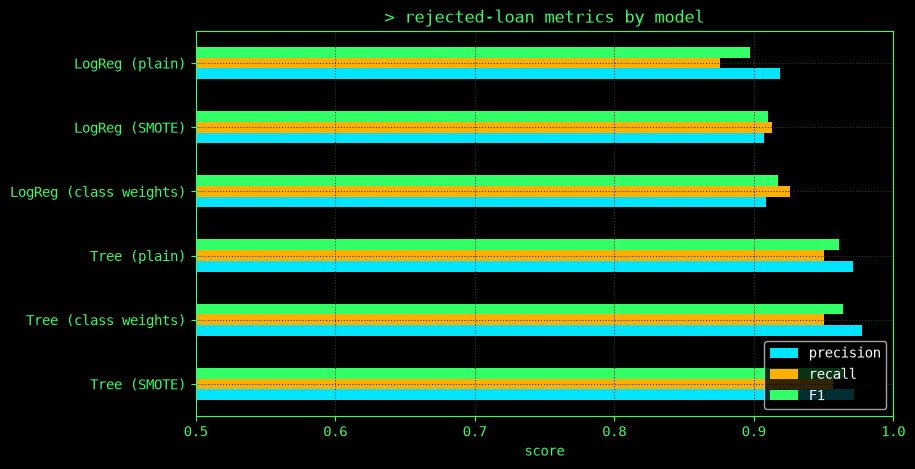

In [10]:
results_df[['precision', 'recall', 'F1']].plot(kind='barh', figsize=(9, 5), color=[CYAN, AMBER, GREEN],
                                               title='> rejected-loan metrics by model')
plt.xlim(0.5, 1.0)
plt.xlabel('score')
plt.legend(loc='lower right')
plt.show()

## 6. Confusion matrices: best logistic regression vs best decision tree

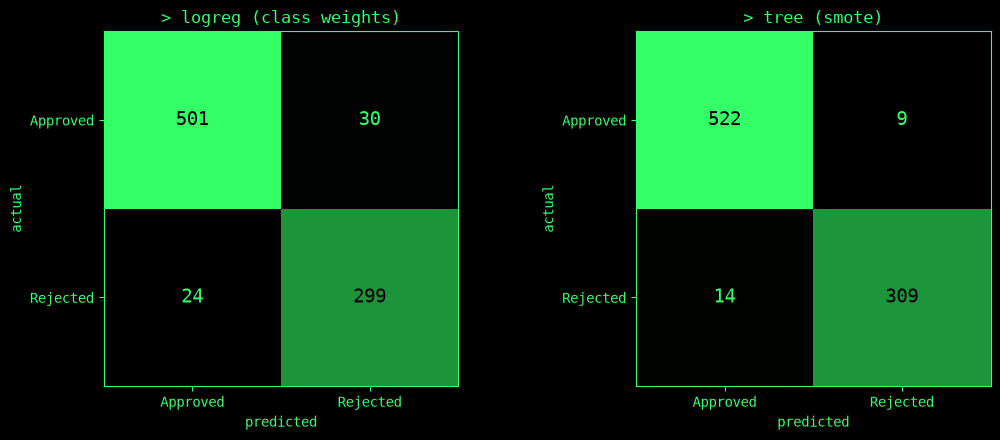

In [11]:
best_lr = results_df.filter(like='LogReg', axis=0).index[0]
best_tree = results_df.filter(like='Tree', axis=0).index[0]
terminal_cmap = LinearSegmentedColormap.from_list('terminal', ['#000000', GREEN])
labels = ['Approved', 'Rejected']

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, [best_lr, best_tree]):
    cm = confusion_matrix(y_test, predictions[name])
    ax.imshow(cm, cmap=terminal_cmap)
    ax.grid(False)
    ax.set_xticks([0, 1], labels)
    ax.set_yticks([0, 1], labels)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=14, color='black' if cm[i, j] > cm.max() / 2 else GREEN)
    ax.set(title=f'> {name.lower()}', xlabel='predicted', ylabel='actual')
plt.tight_layout()
plt.show()

## 7. What drives the decision?

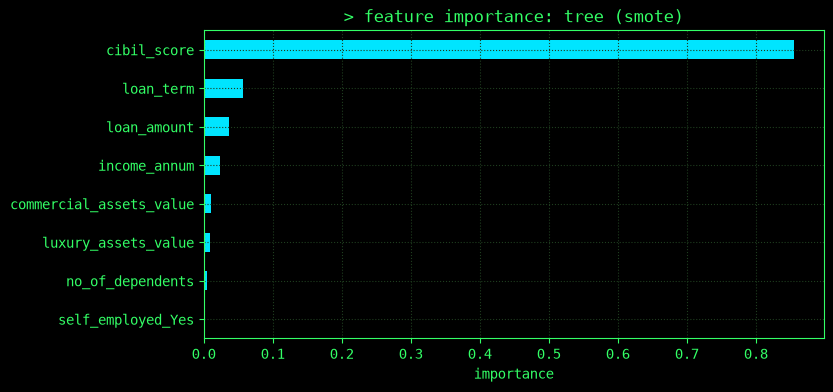

> TOP 5 FEATURES                        
┌─────────────────────────┬────────────┐
│                         │ importance │
├─────────────────────────┼────────────┤
│ cibil_score             │      0.855 │
│ loan_term               │      0.056 │
│ loan_amount             │      0.037 │
│ income_annum            │      0.023 │
│ commercial_assets_value │      0.011 │
└─────────────────────────┴────────────┘

In [12]:
tree_model = models[best_tree]
feature_names = tree_model.named_steps['prep'].get_feature_names_out()
importance = pd.Series(tree_model.named_steps['clf'].feature_importances_, index=feature_names)
importance.index = importance.index.str.replace('num__', '').str.replace('cat__', '')
importance = importance.sort_values(ascending=False)

importance.head(8).sort_values().plot(kind='barh', figsize=(8, 4), color=CYAN, title=f'> feature importance: {best_tree.lower()}')
plt.xlabel('importance')
plt.show()
term_table(importance.head(5).to_frame('importance'), 'TOP 5 FEATURES')

## 8. Conclusions

- **Data:** 4,269 loan applications. There were no empty cells, but **28 negative residential asset values** (impossible) were marked as missing and filled with the median inside the pipeline. Education and self-employment were one-hot encoded.
- **Imbalance:** 62% approved vs 38% rejected, so models were judged on **precision, recall and F1 for rejected loans**, not just accuracy.
- **Logistic regression vs decision tree (bonus):** the decision tree is clearly better: **F1 0.964** vs 0.917 for the best logistic regression.
- **Handling imbalance (bonus):** for logistic regression, class weights raised recall on rejected loans from 0.876 to 0.926 and SMOTE to 0.913, so fewer risky loans slip through. For the decision tree, SMOTE raised recall slightly (0.950 to 0.957) at the same F1.
- **What drives the decision:** the credit score (CIBIL) accounts for 86% of the tree's decisions, far ahead of loan term (6%) and loan amount (4%).
- **Takeaway:** a simple decision tree with SMOTE catches about 96% of loans that should be rejected while staying 97% precise.